--- Cluster Averages ---
         total_wins  pole_conversion_pct
cluster                                 
0               8.2                 68.4
1               7.2                 22.0
2              28.3                 52.3
3              84.5                 69.5 

--- Impact of Pole Conversion Cluster on WDC Standings (2000–2025) ---
 cluster  drivers_in_cluster  avg_wdc_rank  median_wdc_rank  top_3_wdc_finishes  wdc_titles
       0                   5          8.34              7.0                   5           1
       1                   6          8.29              7.0                  15           0
       2                   3          5.14              5.5                  12           6
       3                   2          3.17              3.0                  18          10


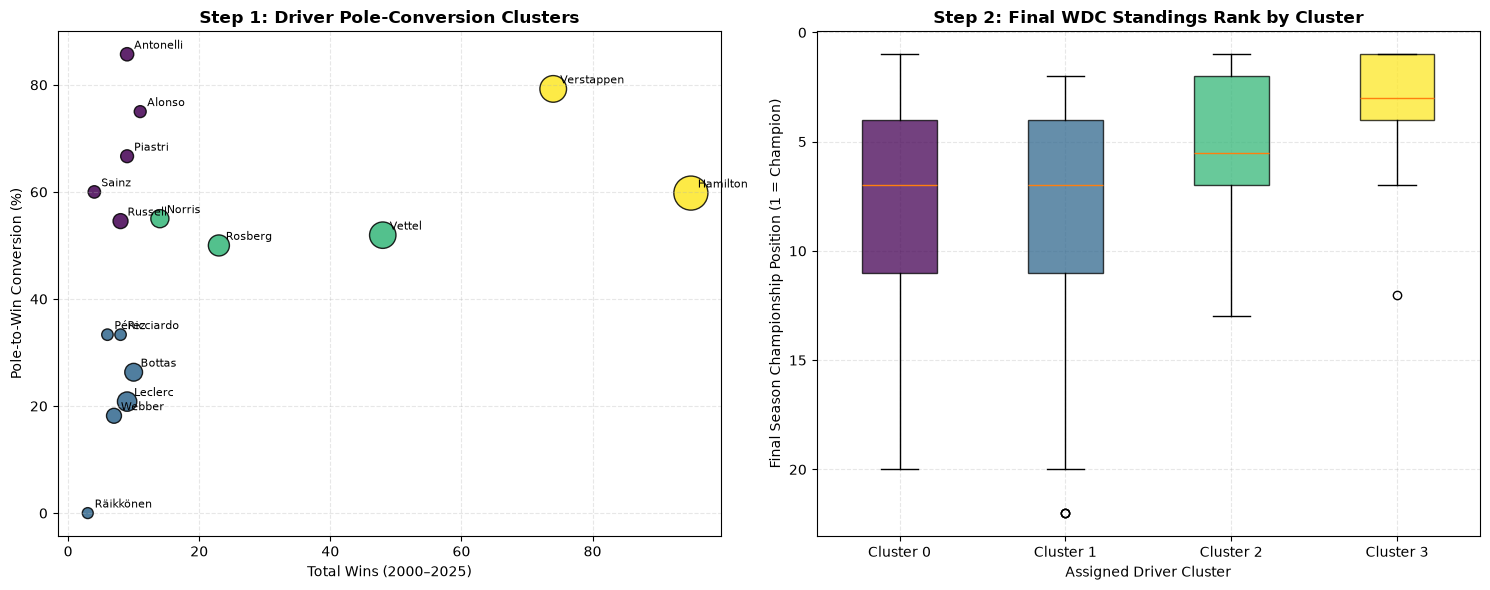

In [ ]:
import pandas as pd 
import numpy as np
import seaborn as sns
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN, OPTICS, HDBSCAN
from sklearn.datasets import make_blobs, make_moons
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score



results = pd.read_csv('../f1/results.csv', na_values='\\N')
races = pd.read_csv('../f1/races.csv', na_values='\\N')
drivers = pd.read_csv('../f1/drivers.csv', na_values='\\N')
qual = pd.read_csv('../f1/qualifying.csv', na_values='\\N')
stand = pd.read_csv('../f1/driver_standings.csv', na_values='\\N')
stat = pd.read_csv('../f1/status.csv', na_values='\\N')
seasons = pd.read_csv('../f1/seasons.csv', na_values='\\N') 


df = (
    results[['raceId', 'driverId', 'positionOrder']]
    .merge(qual[['raceId', 'driverId', 'position']], on=['raceId', 'driverId'], how='inner')
    .merge(races[['raceId', 'year']], on='raceId', how='left')
    .merge(drivers[['driverId', 'forename', 'surname']], on='driverId', how='left')
    .merge(stand[['raceId', 'driverId', 'position']], on=['raceId', 'driverId'], how='left')

)

df = df[(df['year'] >= 2010) & (df['year'] <= 2026)].copy()
df = df.merge(
    results[['raceId', 'driverId', 'grid', 'points']],
    on=['raceId', 'driverId'],
    how='left'
)
df['quali_pos'] = df['position_x'].fillna(df['grid'])
df['driver_name'] = df['forename'] + ' ' + df['surname']

# 3. Calculate career pole conversion & wins per driver (2010–2026)
df['is_win'] = (df['positionOrder'] == 1).astype(int)
df['is_pole'] = (df['quali_pos'] == 1).astype(int)
df['pole_to_win'] = ((df['quali_pos'] == 1) & (df['positionOrder'] == 1)).astype(int)

driver_stats = (
    df.groupby(['driverId', 'driver_name', 'surname'], as_index=False)
    .agg(
        total_wins=('is_win', 'sum'),
        total_poles=('is_pole', 'sum'),
        pole_wins=('pole_to_win', 'sum')
    )
)

# Filter to drivers with at least 2 poles so conversion % isn't skewed by single-pole flukes
driver_stats = driver_stats[driver_stats['total_poles'] >= 2].copy()
driver_stats['pole_conversion_pct'] = (driver_stats['pole_wins'] / driver_stats['total_poles']) * 100

# 4. Run K-Means Clustering (4 clusters)
features = ['total_wins', 'pole_conversion_pct']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(driver_stats[features])

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
driver_stats['cluster'] = kmeans.fit_predict(X_scaled)

# Assign human-readable names to clusters based on their average wins & conversion
cluster_profiles = driver_stats.groupby('cluster')[['total_wins', 'pole_conversion_pct']].mean()
print("--- Cluster Averages ---")
print(cluster_profiles.round(1), "\n")

# 5. Compute Season Driver Standings from race points
season_standings = (
    df.groupby(['year', 'driverId'], as_index=False)
    .agg(season_points=('points', 'sum'), races_entered=('raceId', 'count'))
)

# Rank drivers within each season (1 = World Champion)
season_standings['championship_rank'] = (
    season_standings.groupby('year')['season_points']
    .rank(ascending=False, method='min')
)

# 6. Merge Cluster assignments onto Season Standings
clustered_standings = season_standings.merge(
    driver_stats[['driverId', 'driver_name', 'surname', 'cluster', 'pole_conversion_pct']],
    on='driverId',
    how='inner'
)

# Summary table showing how each cluster performs in the WDC Standings
standings_impact = (
    clustered_standings.groupby('cluster', as_index=False)
    .agg(
        drivers_in_cluster=('driverId', 'nunique'),
        avg_wdc_rank=('championship_rank', 'mean'),
        median_wdc_rank=('championship_rank', 'median'),
        top_3_wdc_finishes=('championship_rank', lambda r: (r <= 3).sum()),
        wdc_titles=('championship_rank', lambda r: (r == 1).sum())
    )
)
print("--- Impact of Pole Conversion Cluster on WDC Standings (2000–2025) ---")
print(standings_impact.round(2).to_string(index=False))

# 7. Plot Side-by-Side Comparison: Clusters vs. Championship Standings Distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left Plot: The Driver Clusters
scatter = axes[0].scatter(
    driver_stats['total_wins'],
    driver_stats['pole_conversion_pct'],
    c=driver_stats['cluster'],
    cmap='viridis',
    s=driver_stats['total_poles'] * 6 + 50,
    alpha=0.85,
    edgecolors='black'
)
for _, row in driver_stats.iterrows():
    axes[0].annotate(
        row['surname'],
        (row['total_wins'], row['pole_conversion_pct']),
        xytext=(5, 4),
        textcoords='offset points',
        fontsize=8
    )
axes[0].set_title('Step 1: Driver Pole-Conversion Clusters', fontweight='bold')
axes[0].set_xlabel('Total Wins (2000–2025)')
axes[0].set_ylabel('Pole-to-Win Conversion (%)')
axes[0].grid(True, linestyle='--', alpha=0.3)

# Right Plot: Boxplot of Final Championship Position by Cluster
clusters_sorted = sorted(clustered_standings['cluster'].unique())
box_data = [
    clustered_standings[clustered_standings['cluster'] == c]['championship_rank']
    for c in clusters_sorted
]

bp = axes[1].boxplot(
    box_data,
    tick_labels=[f'Cluster {c}' for c in clusters_sorted],
    patch_artist=True
)
colors = plt.cm.viridis([c / max(clusters_sorted) for c in clusters_sorted])
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

axes[1].invert_yaxis()  # Put 1st place (Champion) at the top
axes[1].set_title('Step 2: Final WDC Standings Rank by Cluster', fontweight='bold')
axes[1].set_xlabel('Assigned Driver Cluster')
axes[1].set_ylabel('Final Season Championship Position (1 = Champion)')
axes[1].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()
